In [7]:
import pandas as pd

raw = pd.read_parquet("data/train-00000-of-00001.parquet")
raw.shape # (rows, columns)
raw.head() # the first 5 films
raw.info() # column names, types, missing values

<class 'pandas.DataFrame'>
RangeIndex: 124146 entries, 0 to 124145
Data columns (total 41 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   appID                     124146 non-null  str    
 1   name                      124146 non-null  str    
 2   release_date              124146 non-null  str    
 3   estimated_owners          124146 non-null  str    
 4   peak_ccu                  124146 non-null  int64  
 5   required_age              124146 non-null  int64  
 6   price                     124146 non-null  float64
 7   dlc_count                 124146 non-null  int64  
 8   detailed_description      124146 non-null  str    
 9   short_description         124146 non-null  str    
 10  supported_languages       124146 non-null  object 
 11  full_audio_languages      124146 non-null  object 
 12  reviews                   124146 non-null  str    
 13  header_image              124146 non-null  str    
 14 

In [8]:
raw.describe()

,peak_ccu,required_age,price,dlc_count,metacritic_score,user_score,positive,negative,achievements,recommendations,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks
count,1.241460e+05,124146.000000,124146.000000,124146.000000,124146.000000,124146.000000,1.241460e+05,1.241460e+05,124146.000000,1.241460e+05,1.241460e+05,124146.000000,1.241460e+05,124146.000000
mean,5.391834e+01,0.166151,4.786144,0.540573,2.533855,0.024246,1.032103e+03,1.671155e+02,18.010520,9.501171e+02,2.054626e+02,13.628204,1.714364e+02,14.550578
std,3.706328e+03,1.646332,12.507614,14.426264,13.580489,1.386253,2.791776e+04,5.341348e+03,140.633042,2.174339e+04,1.114814e+04,268.710314,1.113308e+04,292.692992
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,0.000000e+00,0.000000,0.550000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
50%,0.000000e+00,0.000000,2.390000,0.000000,0.000000,0.000000,5.000000e+00,1.000000e+00,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
75%,0.000000e+00,0.000000,5.390000,0.000000,0.000000,0.000000,3.600000e+01,1.000000e+01,19.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
max,1.013936e+06,21.000000,999.980000,3703.000000,97.000000,100.000000,7.642084e+06,1.173003e+06,9821.000000,4.830455e+06,3.429544e+06,20088.000000,3.429544e+06,20088.000000


In [9]:
raw.isna().sum()

appID                       0
name                        0
release_date                0
estimated_owners            0
peak_ccu                    0
required_age                0
price                       0
dlc_count                   0
detailed_description        0
short_description           0
supported_languages         0
full_audio_languages        0
reviews                     0
header_image                0
website                     0
support_url                 0
support_email               0
windows                     0
mac                         0
linux                       0
metacritic_score            0
metacritic_url              0
user_score                  0
positive                    0
negative                    0
score_rank                  0
achievements                0
recommendations             0
notes                       0
average_playtime_forever    0
average_playtime_2weeks     0
median_playtime_forever     0
median_playtime_2weeks      0
developers

In [122]:
classification = {
    "appID": "Identification",
    "name": "NonApplicable",
    "release_date": "Applicable",
    "estimated_owners": "Leakage",
    "peak_ccu": "Leakage",
    "required_age": "Applicable",
    "price": "Applicable",
    "dlc_count": "Leakage",
    "detailed_description": "Applicable (difficult)",
    "short_description": "Applicable (difficult)",
    "supported_languages": "Applicable",
    "full_audio_languages": "Applicable",
    "reviews": "Leakage",
    "header_image": "NonApplicable",
    "website": "NonApplicable",
    "support_url": "NonApplicable",
    "support_email": "NonApplicable",
    "windows": "Applicable",
    "mac": "Applicable",
    "linux": "Applicable",
    "metacritic_score": "Leakage",
    "metacritic_url": "NonApplicable",
    "user_score": "Leakage",
    "positive": "Leakage",
    "negative": "Leakage",
    "score_rank": "Leakage",
    "achievements": "NonApplicable",
    "recommendations": "Leakage",
    "notes": "Applicable (difficult)",
    "average_playtime_forever": "Leakage",
    "average_playtime_2weeks": "Leakage",
    "median_playtime_forever": "Leakage",
    "median_playtime_2weeks": "Leakage",
    "developers": "Applicable",
    "publishers": "Applicable",
    "categories": "Applicable",
    "genres": "Applicable",
    "tags": "NonApplicable / Leakage",
    "screenshots": "NonApplicable",
    "movies": "NonApplicable",
    "packages": "NonApplicable",
}

columns_overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "classification": pd.Series(classification),
})
columns_overview.index.name = "column"

columns_overview

,dtype,classification
column,,
appID,str,Identification
name,str,NonApplicable
release_date,str,Applicable
estimated_owners,str,Leakage
peak_ccu,int64,Leakage
required_age,int64,Applicable
price,float64,Applicable
dlc_count,int64,Leakage
detailed_description,str,Applicable (difficult)


In [133]:
usable_cols = columns_overview.index[
    ~columns_overview["classification"].str.contains("NonApplicable")
]

software_genres = {
    "Game Development", "Design & Illustration", "Animation & Modeling",
    "Utilities", "Video Production", "Software Training", "Audio Production",
    "Photo Editing", "Web Publishing", "Accounting", "Education",
}

def is_software(genres):
    genres = set(genres) if genres is not None else set()
    return len(genres) == 0 or genres <= software_genres

df = raw[usable_cols]

df = df[~df["genres"].apply(is_software)]

df.info()

<class 'pandas.DataFrame'>
Index: 114522 entries, 1 to 124145
Data columns (total 30 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   appID                     114522 non-null  str    
 1   release_date              114522 non-null  str    
 2   estimated_owners          114522 non-null  str    
 3   peak_ccu                  114522 non-null  int64  
 4   required_age              114522 non-null  int64  
 5   price                     114522 non-null  float64
 6   dlc_count                 114522 non-null  int64  
 7   detailed_description      114522 non-null  str    
 8   short_description         114522 non-null  str    
 9   supported_languages       114522 non-null  object 
 10  full_audio_languages      114522 non-null  object 
 11  reviews                   114522 non-null  str    
 12  windows                   114522 non-null  bool   
 13  mac                       114522 non-null  bool   
 14  linu

In [134]:
mask = (
    (columns_overview["classification"].str.contains("NonApplicable")) |
    (columns_overview["classification"].str.contains("Leakage")) |
    (columns_overview["classification"].str.contains("difficult"))
)

feature_cols = columns_overview.index[
    ~mask
]

features_list = raw[feature_cols]

features_list.info()

<class 'pandas.DataFrame'>
RangeIndex: 124146 entries, 0 to 124145
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   appID                 124146 non-null  str    
 1   release_date          124146 non-null  str    
 2   required_age          124146 non-null  int64  
 3   price                 124146 non-null  float64
 4   supported_languages   124146 non-null  object 
 5   full_audio_languages  124146 non-null  object 
 6   windows               124146 non-null  bool   
 7   mac                   124146 non-null  bool   
 8   linux                 124146 non-null  bool   
 9   developers            124146 non-null  object 
 10  publishers            124146 non-null  object 
 11  categories            124146 non-null  object 
 12  genres                124146 non-null  object 
dtypes: bool(3), float64(1), int64(1), object(6), str(2)
memory usage: 12.0+ MB


In [135]:
df = df[(df["positive"] + df["negative"]) >= 10]
df["year"] = pd.to_datetime(df["release_date"], errors="coerce").dt.year
df["score"] = df["positive"] / (df["positive"] + df["negative"]) * 100
threshold = df.groupby("year")["score"].transform("quantile", 0.75)
df["hit"] = df["score"] >= threshold
df["language_count"] = df["supported_languages"].str.len().fillna(0).astype(int)
df["audio_count"] = df["full_audio_languages"].str.len().fillna(0).astype(int)

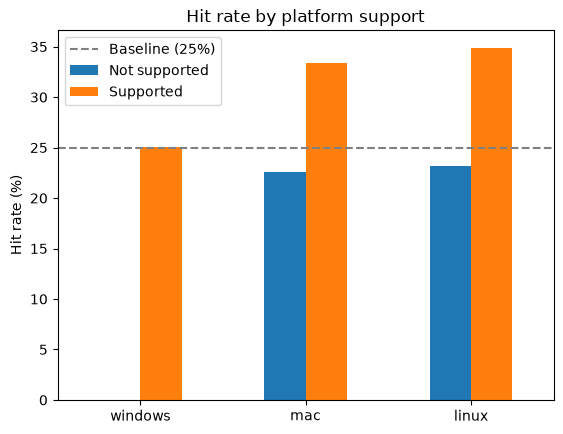

,Not supported,Supported
windows,0.000000,25.081340
mac,22.546481,33.381768
linux,23.194646,34.873158


In [136]:
import matplotlib.pyplot as plt
import numpy as np
import json

platforms = ["windows", "mac", "linux"]

hit_rates = pd.DataFrame({
    p: df.groupby(p)["hit"].mean() * 100 for p in platforms
}).T.rename(columns={False: "Not supported", True: "Supported"})

hit_rates.plot(kind="bar", rot=0)
plt.axhline(25, color="grey", linestyle="--", label="Baseline (25%)")
plt.ylabel("Hit rate (%)")
plt.title("Hit rate by platform support")
plt.legend()
plt.show()

hit_rates

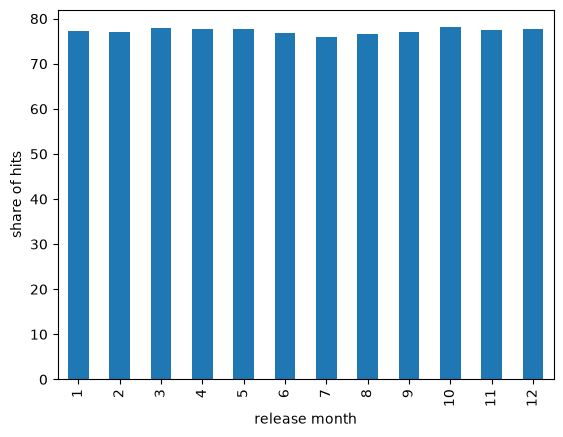

In [137]:
df["month"] = pd.to_datetime(df["release_date"], errors="coerce").dt.month

df["score"].groupby(df["month"]).mean().plot.bar()
plt.xlabel("release month")
plt.ylabel("share of hits")
plt.show()

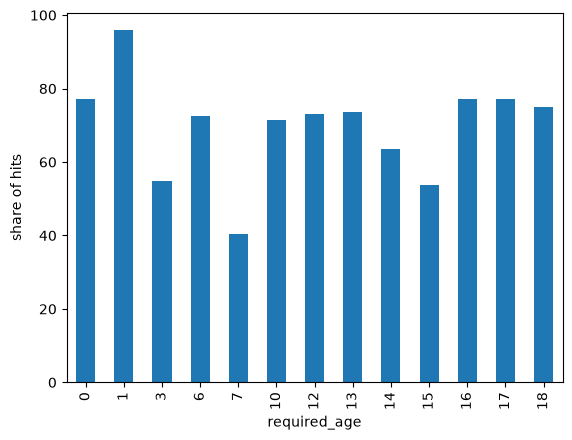

In [138]:
df["score"].groupby(df["required_age"]).mean().plot.bar()
plt.xlabel("required_age")
plt.ylabel("share of hits")
plt.show()

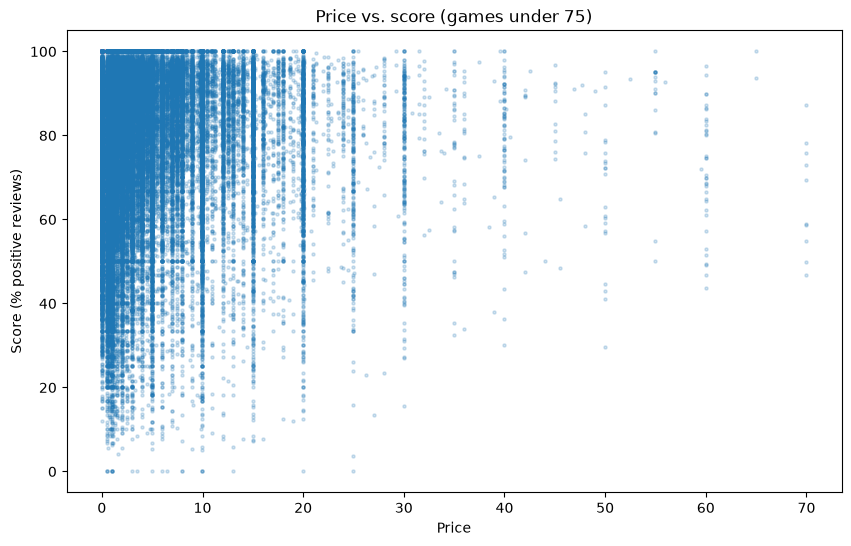

In [139]:
under_75 = df[df["price"] < 75]

plt.figure(figsize=(10, 6))
plt.scatter(under_75["price"], under_75["score"], s=5, alpha=0.2)
plt.xlabel("Price")
plt.ylabel("Score (% positive reviews)")
plt.title("Price vs. score (games under 75)")
plt.show()

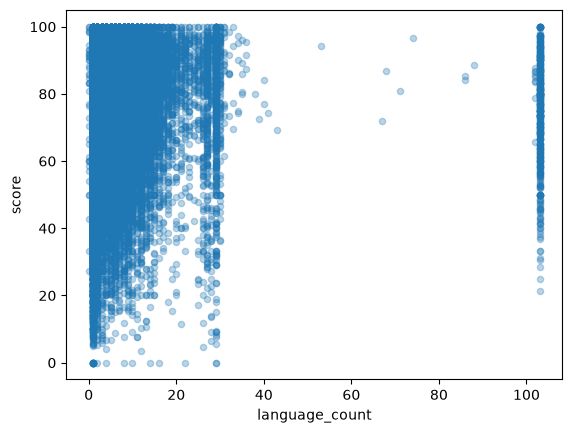

In [140]:
df.plot.scatter(x="language_count", y="score", alpha=0.3)
plt.show()

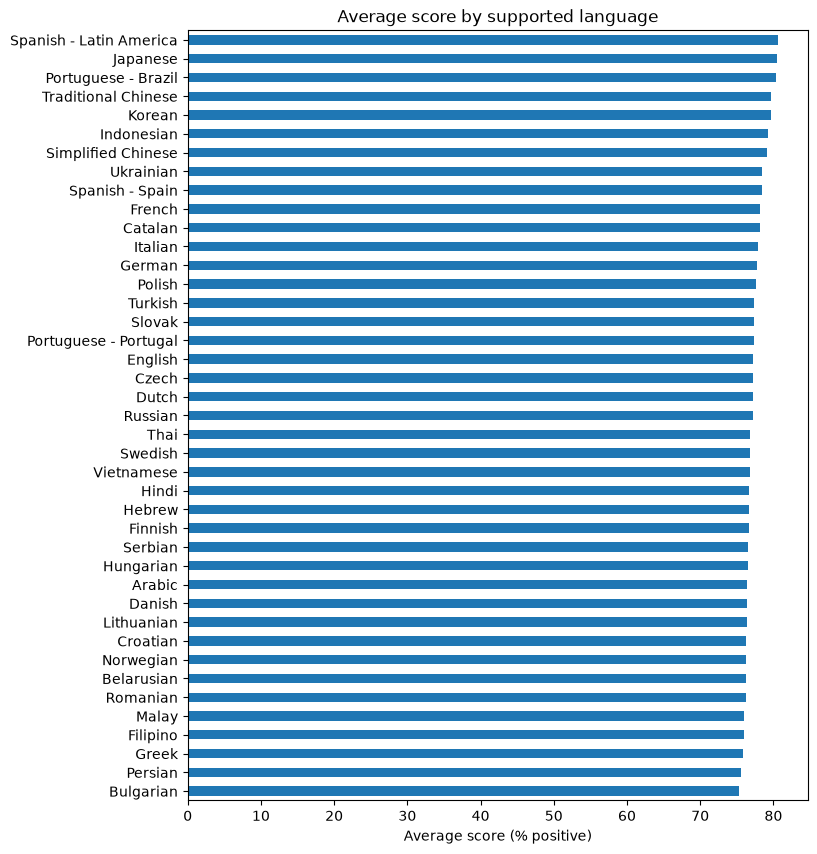

In [141]:
langs = df[["supported_languages", "score"]].explode("supported_languages")

per_lang = (
    langs.groupby("supported_languages")["score"]
         .agg(["mean", "count"])
         .query("count >= 500")          # leave out rare languages
         .sort_values("mean")
)

per_lang["mean"].plot(kind="barh", figsize=(8, 10))
plt.xlabel("Average score (% positive)")
plt.ylabel("")
plt.title("Average score by supported language")
plt.show()

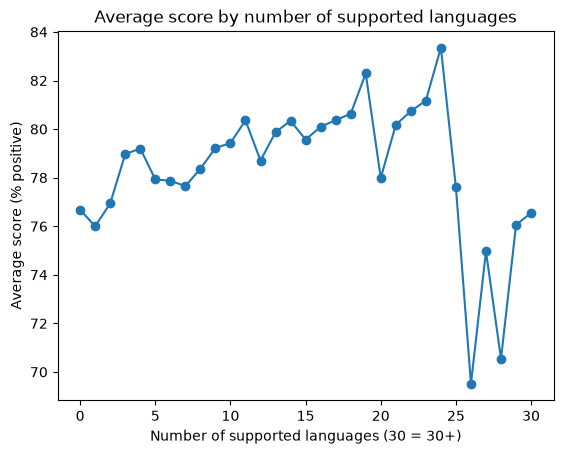

In [142]:
lang_score = (
    df.assign(lang_bin=df["language_count"].clip(upper=30))   # put 30+ languages in one group
      .groupby("lang_bin")["score"]
      .agg(["mean", "count"])
)

lang_score["mean"].plot(marker="o")
plt.xlabel("Number of supported languages (30 = 30+)")
plt.ylabel("Average score (% positive)")
plt.title("Average score by number of supported languages")
plt.show()

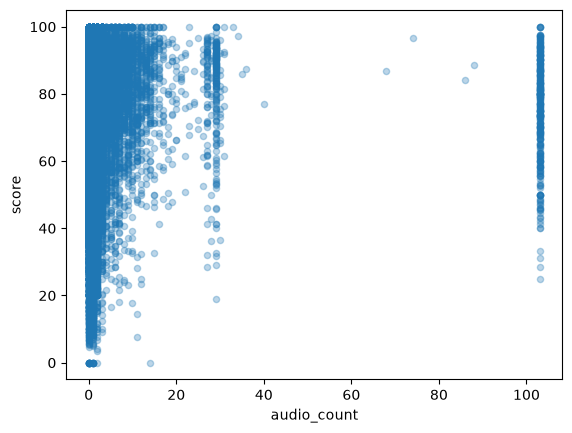

In [143]:
df.plot.scatter(x="audio_count", y="score", alpha=0.3)
plt.show()

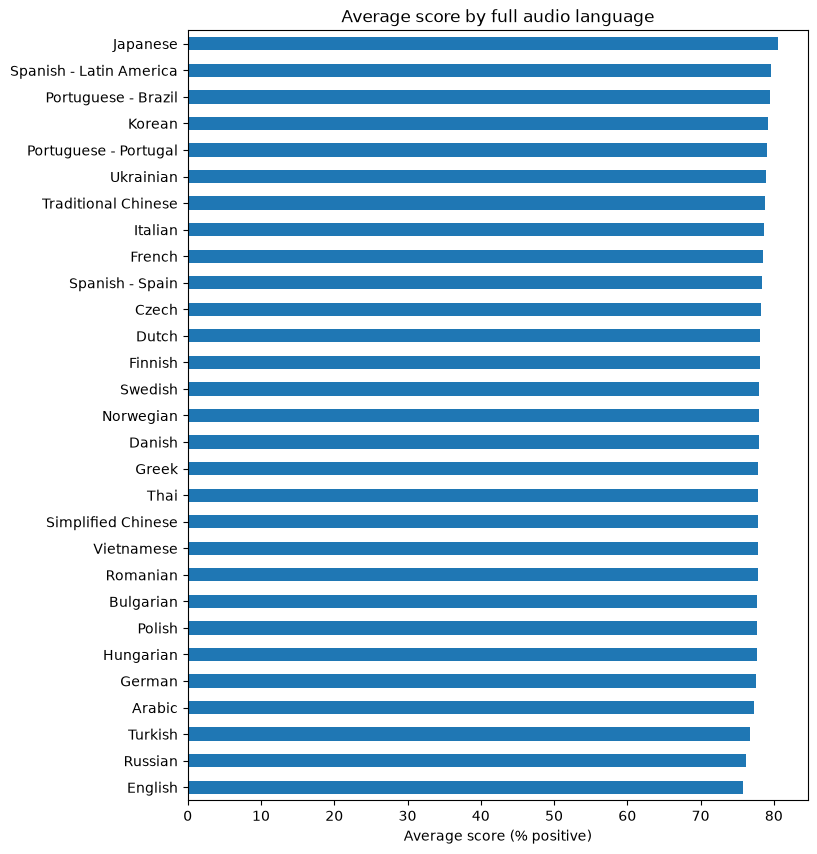

In [144]:
audio = df[["full_audio_languages", "score"]].explode("full_audio_languages")

per_audio = (
    audio.groupby("full_audio_languages")["score"]
         .agg(["mean", "count"])
         .query("count >= 500")          # leave out rare languages
         .sort_values("mean")
)

per_audio["mean"].plot(kind="barh", figsize=(8, 10))
plt.xlabel("Average score (% positive)")
plt.ylabel("")
plt.title("Average score by full audio language")
plt.show()

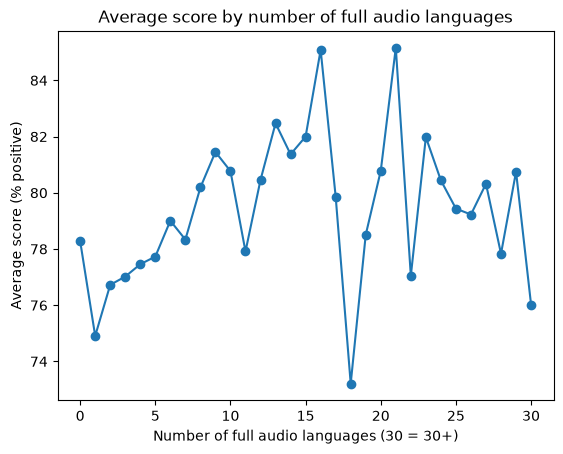

In [145]:
audio_score = (
    df.assign(lang_bin=df["audio_count"].clip(upper=30))   # put 30+ languages in one group
      .groupby("lang_bin")["score"]
      .agg(["mean", "count"])
)

audio_score["mean"].plot(marker="o")
plt.xlabel("Number of full audio languages (30 = 30+)")
plt.ylabel("Average score (% positive)")
plt.title("Average score by number of full audio languages")
plt.show()

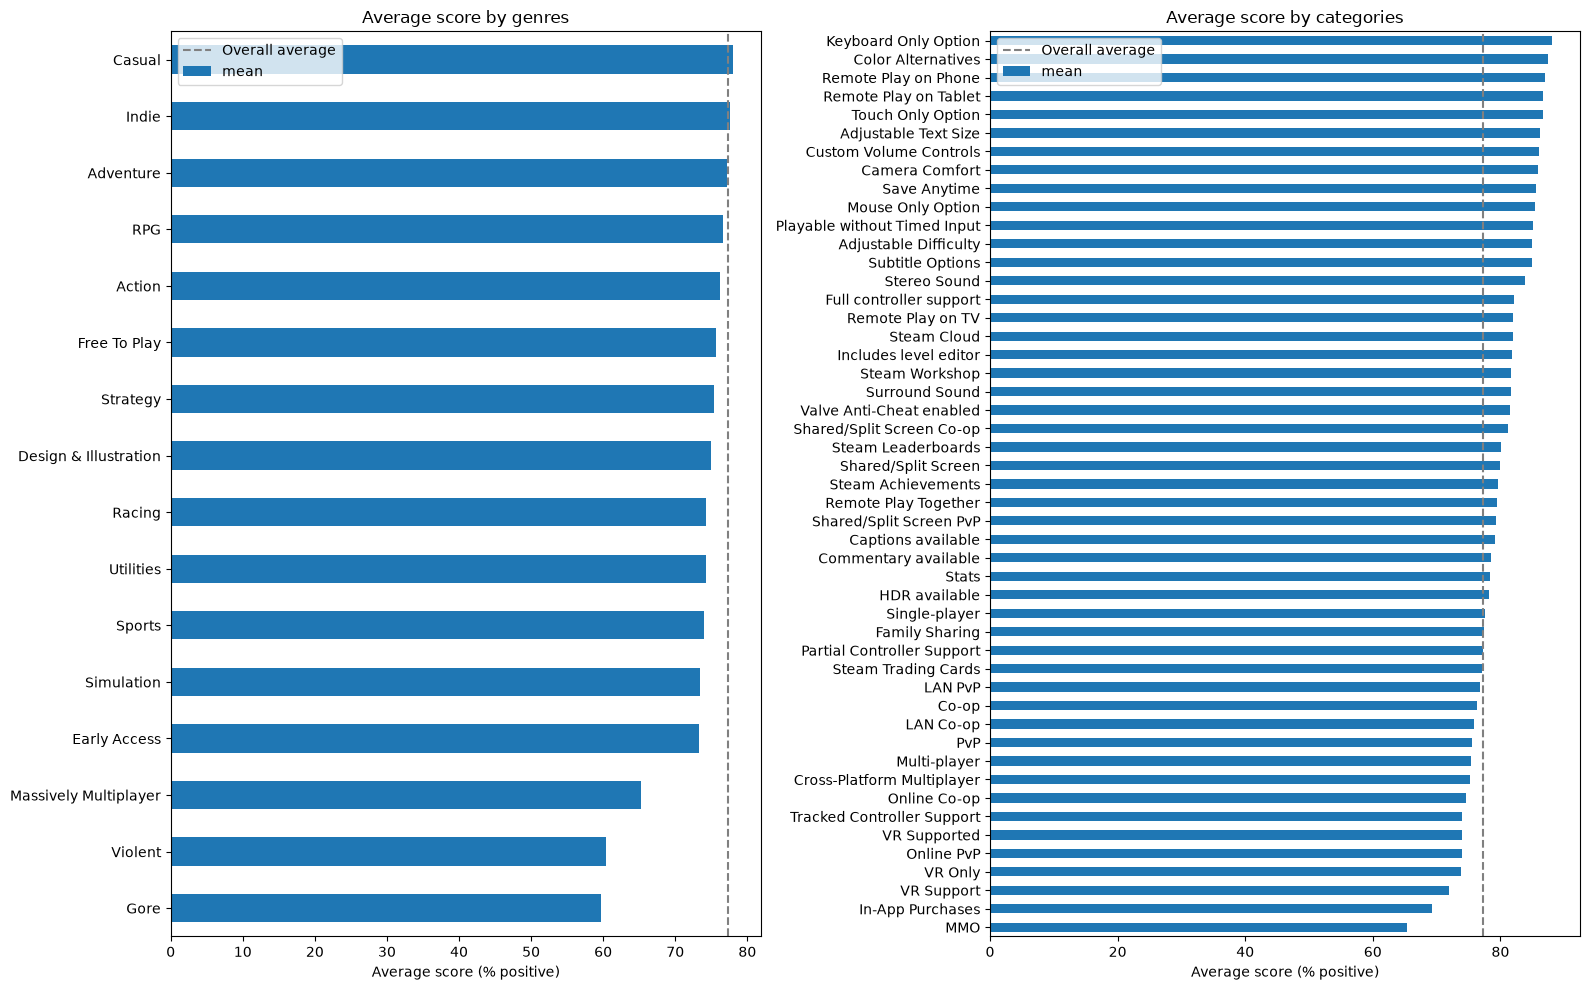

In [146]:
def plot_avg_score(df, col, min_games=100, ax=None):
    stats = (
        df[[col, "score"]]
        .explode(col)
        .groupby(col)["score"]
        .agg(["mean", "count"])
        .query("count >= @min_games")
        .sort_values("mean")
    )
    stats["mean"].plot(kind="barh", ax=ax)
    ax.axvline(df["score"].mean(), color="grey", linestyle="--", label="Overall average")
    ax.set_xlabel("Average score (% positive)")
    ax.set_ylabel("")
    ax.set_title(f"Average score by {col}")
    ax.legend()
    return stats

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
genre_stats = plot_avg_score(df, "genres", ax=axes[0])
category_stats = plot_avg_score(df, "categories", ax=axes[1])
plt.tight_layout()
plt.show()

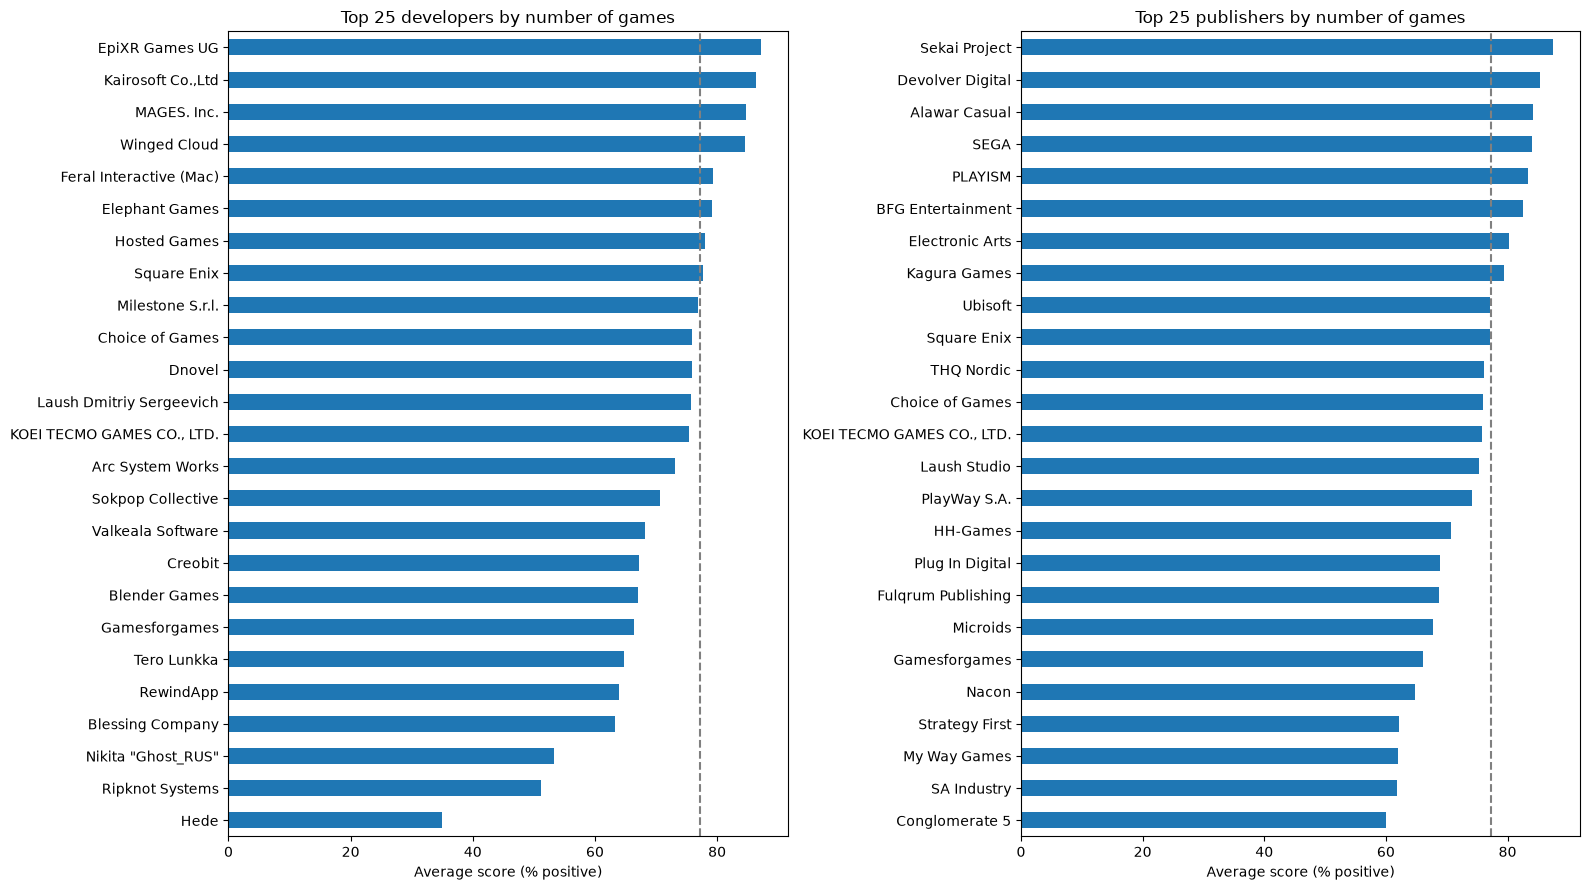

In [147]:
def plot_top_by_count(df, col, top_n=25, ax=None):
    stats = (
        df[[col, "score"]]
        .explode(col)
        .groupby(col)["score"]
        .agg(["mean", "count"])
        .nlargest(top_n, "count")
        .sort_values("mean")
    )
    stats["mean"].plot(kind="barh", ax=ax)
    ax.axvline(df["score"].mean(), color="grey", linestyle="--")
    ax.set_xlabel("Average score (% positive)")
    ax.set_ylabel("")
    ax.set_title(f"Top {top_n} {col} by number of games")
    return stats

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
plot_top_by_count(df, "developers", ax=axes[0])
plot_top_by_count(df, "publishers", ax=axes[1])
plt.tight_layout()
plt.show()

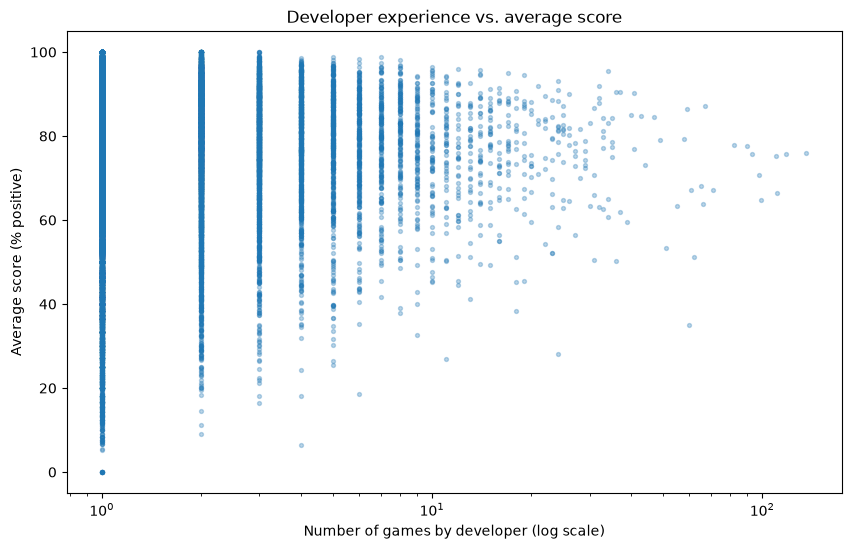

In [157]:
dev_stats = (
    df[["developers", "score"]]
    .explode("developers")
    .groupby("developers")["score"]
    .agg(["mean", "count"])
)

plt.figure(figsize=(10, 6))
plt.scatter(dev_stats["count"], dev_stats["mean"], s=8, alpha=0.3)
plt.xscale("log")
plt.xlabel("Number of games by developer (log scale)")
plt.ylabel("Average score (% positive)")
plt.title("Developer experience vs. average score")
plt.show()

dev_count = dev_stats["count"]
dev_mean = dev_stats["mean"]

df["dev_game_count"] = df["developers"].apply(
    lambda devs: max((dev_count.get(d, 0) for d in devs), default=0)
)

In [149]:
df["self_published"] = df.apply(
    lambda r: len(set(r["developers"]) & set(r["publishers"])) > 0, axis=1
)
df.groupby("self_published")[["score", "hit"]].mean()

,score,hit
self_published,,
False,76.101132,0.220211
True,77.776570,0.263974


In [159]:
from sklearn.model_selection import train_test_split
df_tmp, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_tmp, test_size=0.25, random_state=42)
len(df_train), len(df_val), len(df_test)

(33565, 11189, 11189)

In [160]:
features = [
    "price", "language_count", "self_published", "linux", "mac", "audio_count", "dev_game_count"
]

X_train, y_train = df_train[features], df_train["hit"]
X_val,   y_val   = df_val[features],   df_val["hit"]
X_test,  y_test  = df_test[features],  df_test["hit"]

In [161]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
model = LogisticRegression(max_iter=1000,class_weight="balanced")
model.fit(X_train, y_train)
pred_baseline = baseline.predict(X_val)
pred_model = model.predict(X_val)
print("Baseline:", accuracy_score(y_val, pred_baseline), recall_score(y_val, pred_baseline))
print("Model: ", accuracy_score(y_val, pred_model), recall_score(y_val, pred_model))

Baseline: 0.7544910179640718 0.0
Model:  0.6635088032889445 0.3403713141609028
